# [Lab Session 2](otsu.ipynb)

In [21]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 2.1.]()** Implement Otsu thresholding as a re-usable function:

In [22]:
def otsu_thresholding(imgf):
    img8 = (imgf * 255).round().astype(np.uint8)
    h = np.zeros(256)
    for i in range(256) :
        h[i] = np.sum(img8 == i)
    sum_wcv = np.zeros(256)
    for T in range(256) :
        sum_wcv[T] = (np.sum(h[:T]) * np.var(img8[img8 < T]) + (np.sum(h[T:]) * np.var(img8[img8 >= T])))
    T_best = np.nanargmin(sum_wcv)
    img8_otsu = img8.copy()

    for x in range(img8.shape[0]) :
        for y in range(img8.shape[1]) :
            if img8[x, y] > T_best :
                img8_otsu[x, y] = 255
            else :
                img8_otsu[x, y] = 0

    imgf_otsu = img8_otsu / 255
    
    
    return imgf_otsu

**[Task 2.2.]()** Implement a re-usable function to compute the Dice coefficient:

In [23]:
def compute_dice(bin1, bin2):
    return (2 * (bin1 * bin2).sum()) / (bin1.sum() + bin2.sum())

**[Task 2.3.]()** Test your implementations from above:

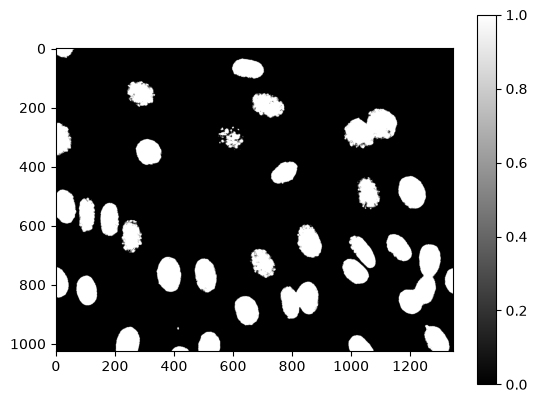

In [24]:
imgf_test = plt.imread("data/NIH3T3/im/dna-0.png")
imgf_test_otsu = otsu_thresholding(imgf_test)
plt.figure()
plt.imshow(imgf_test_otsu, cmap="gray")
plt.colorbar()

In [25]:
imgf_gt = plt.imread("data/NIH3T3/gt/0.png")

dice_imgf_test = compute_dice(imgf_test_otsu, imgf_gt)
dice_imgf_test

np.float64(0.8701113873987207)

The result should be the same as in your [otsu.ipynb](otsu.ipynb) notebook.

**[Task 2.4.]()** Perform batch processing:

In [26]:
imgs = {}
imgs_otsu = {}
imgs_gt = {}
imgs_dice = {}
for i in [28, 29, 33, 44, 46, 49] :
    imgs["dna-" + str(i)] = plt.imread("data/NIH3T3/im/dna-" + str(i) + ".png")
    imgs_otsu["imgf_" + str(i) + "_otsu"] = otsu_thresholding(imgs["dna-" + str(i)])
    imgs_gt["imgf_" + str(i) + "_gt"] = plt.imread("data/NIH3T3/gt/" + str(i) + ".png")
    imgs_dice["dice_imgf_" + str(i)] = compute_dice(imgs_otsu["imgf_" + str(i) + "_otsu"], imgs_gt["imgf_" + str(i) + "_gt"])
    print("dice coefficient for dna-" + str(i) + ": " + str(imgs_dice['dice_imgf_' + str(i)]))

print("Average dice coefficient: " + str(np.mean(list(imgs_dice.values()))))

dice coefficient for dna-28: 0.7304073649082119
dice coefficient for dna-29: 0.6173457425410247
dice coefficient for dna-33: 0.41139959577597857
dice coefficient for dna-44: 0.5757554586315079
dice coefficient for dna-46: 0.07006108309760997
dice coefficient for dna-49: 0.795511933063147
Average dice coefficient: 0.53341352966958
